<a href="https://colab.research.google.com/github/braysonimbambi455/CSC4110-G03/blob/main/G03_U3_2_poly_regularisation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CSC 4110 — Task 3.2: Polynomial and Regularised Regression

**Owner:** Austin Gatita  
**Group:** G03 — Crop Yield  
**Module:** 4 — Regression

This notebook continues the group's Task 2.2 and Task 3.1 work. It uses `data/clean_crops.csv`, predicts `log_yield`, and preserves the chronological split: training years through 2009 and test years 2010–2013. The standard scaler is fitted on training features only.

**Required evidence:** `poly_results`, `ridge_results`, `lasso_results`, `results_reg`, `outputs/under_over_fit.png`, and `outputs/regression_comparison.png`.

In [16]:
# Mount Google Drive when running this notebook in Google Colab.
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [17]:

# Import libraries and define the shared group project folders.
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Point to the complete group project folder.
BASE = "/content/drive/MyDrive/CSC4110_G03 (1)"

DATA = os.path.join(BASE, "data")
OUT = os.path.join(BASE, "outputs")
os.makedirs(OUT, exist_ok=True)

print("Project folder:", BASE)
print("Data folder exists:", os.path.exists(DATA))
print("Output folder exists:", os.path.exists(OUT))
print("Files in data folder:", os.listdir(DATA))


Project folder: /content/drive/MyDrive/CSC4110_G03 (1)
Data folder exists: True
Output folder exists: True
Files in data folder: ['yield_df.csv', 'stage1_crops.csv', 'clean_crops.csv']


In [18]:
# Load the transformed dataset prepared by Simon in Task 2.2.
df = pd.read_csv(os.path.join(DATA, "clean_crops.csv"))
print("Dataset shape:", df.shape)
display(df.head())
print("Columns:", df.columns.tolist())

Dataset shape: (25932, 19)


,Item,Year,yield_hg_ha,rain_mm,pesticides_t,avg_temp,log_yield,Area_frequency,Item_Cassava,Item_Maize,Item_Plantains and others,Item_Potatoes,"Item_Rice, paddy",Item_Sorghum,Item_Soybeans,Item_Sweet potatoes,Item_Wheat,Item_Yams,years_since_1990
0,Maize,1990,36613,1485.0,121.0,16.37,10.508159,0.003818,0,1,0,0,0,0,0,0,0,0,0
1,Potatoes,1990,66667,1485.0,121.0,16.37,11.107465,0.003818,0,0,0,1,0,0,0,0,0,0,0
2,"Rice, paddy",1990,23333,1485.0,121.0,16.37,10.057624,0.003818,0,0,0,0,1,0,0,0,0,0,0
3,Sorghum,1990,12500,1485.0,121.0,16.37,9.433484,0.003818,0,0,0,0,0,1,0,0,0,0,0
4,Soybeans,1990,7000,1485.0,121.0,16.37,8.853665,0.003818,0,0,0,0,0,0,1,0,0,0,0


Columns: ['Item', 'Year', 'yield_hg_ha', 'rain_mm', 'pesticides_t', 'avg_temp', 'log_yield', 'Area_frequency', 'Item_Cassava', 'Item_Maize', 'Item_Plantains and others', 'Item_Potatoes', 'Item_Rice, paddy', 'Item_Sorghum', 'Item_Soybeans', 'Item_Sweet potatoes', 'Item_Wheat', 'Item_Yams', 'years_since_1990']


In [19]:
# Recreate Jacob's numeric feature set and the same chronological train-test split.
drop_cols = ["yield_hg_ha", "log_yield", "Year", "Area"]
X = df.drop(columns=[c for c in drop_cols if c in df.columns])
X = X.select_dtypes(include=[np.number])
y = df["log_yield"]

train_mask = df["Year"] <= 2009
test_mask = (df["Year"] >= 2010) & (df["Year"] <= 2013)

X_train_raw = X.loc[train_mask].copy()
X_test_raw = X.loc[test_mask].copy()
y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

print("Training years:", df.loc[train_mask, "Year"].min(), "to", df.loc[train_mask, "Year"].max())
print("Testing years:", df.loc[test_mask, "Year"].min(), "to", df.loc[test_mask, "Year"].max())
print("Training rows:", len(X_train_raw), "| Test rows:", len(X_test_raw))

Training years: 1990 to 2009
Testing years: 2010 to 2013
Training rows: 21305 | Test rows: 4627


In [20]:
# Fit the same StandardScaler approach as Task 3.1 using training data only.
scaler = StandardScaler()
X_train = pd.DataFrame(
    scaler.fit_transform(X_train_raw),
    columns=X.columns,
    index=X_train_raw.index
)
X_test = pd.DataFrame(
    scaler.transform(X_test_raw),
    columns=X.columns,
    index=X_test_raw.index
)

def calculate_rmse(actual, predicted):
    # Calculate root mean squared error for model comparison.
    return float(np.sqrt(mean_squared_error(actual, predicted)))

print("Scaled training shape:", X_train.shape)
print("Scaled testing shape:", X_test.shape)

Scaled training shape: (21305, 15)
Scaled testing shape: (4627, 15)


## Part A — Polynomial regression

The polynomial models use only the scaled `avg_temp` feature, as required. Degrees 1, 2 and 3 are evaluated using training and test RMSE. The scaler above was fitted only on the training period and is reused for the test period.

In [21]:
# Fit polynomial regression pipelines for degrees 1, 2 and 3 and record both RMSE values.
poly_models = {}
poly_rows = []

for degree in [1, 2, 3]:
    poly_pipe = Pipeline([
        ("polynomial_features", PolynomialFeatures(degree=degree, include_bias=False)),
        ("linear_regression", LinearRegression())
    ])
    poly_pipe.fit(X_train[["avg_temp"]], y_train)

    train_prediction = poly_pipe.predict(X_train[["avg_temp"]])
    test_prediction = poly_pipe.predict(X_test[["avg_temp"]])

    poly_models[degree] = poly_pipe
    poly_rows.append({
        "degree": degree,
        "train_RMSE": calculate_rmse(y_train, train_prediction),
        "test_RMSE": calculate_rmse(y_test, test_prediction)
    })

poly_results = pd.DataFrame(poly_rows).sort_values("degree").reset_index(drop=True)
display(poly_results)

,degree,train_RMSE,test_RMSE
0,1,1.097719,1.116247
1,2,1.097388,1.115533
2,3,1.092724,1.111108


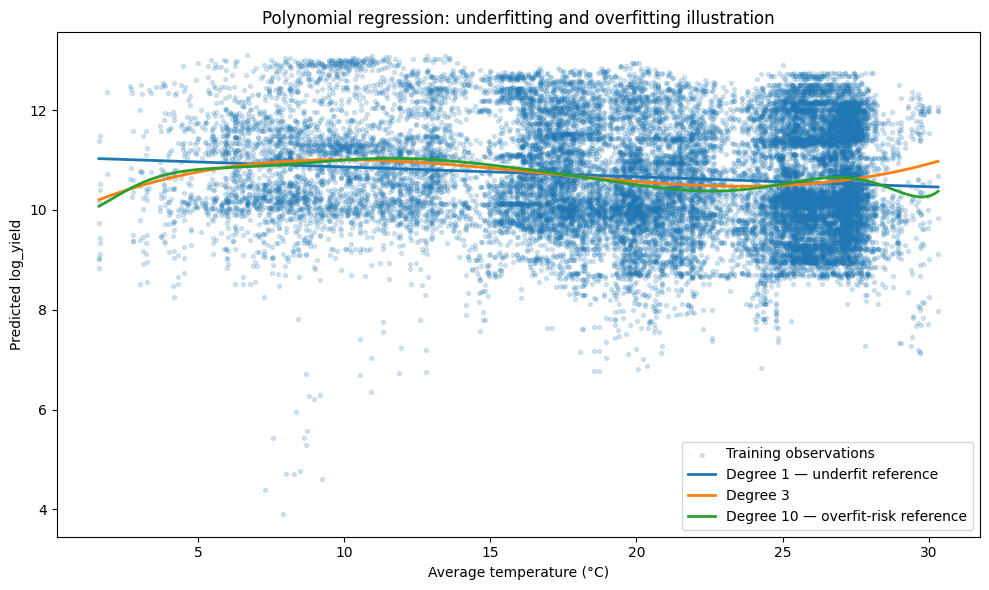

,degree,train_RMSE,test_RMSE
0,1,1.097719,1.116247
1,3,1.092724,1.111108
2,10,1.089605,1.107949


In [22]:
# Plot degree 1, 3 and 10 temperature curves and save the under/overfitting illustration.
curve_models = {}
for degree in [1, 3, 10]:
    curve_pipe = Pipeline([
        ("polynomial_features", PolynomialFeatures(degree=degree, include_bias=False)),
        ("linear_regression", LinearRegression())
    ])
    curve_pipe.fit(X_train[["avg_temp"]], y_train)
    curve_models[degree] = curve_pipe

temperature_grid = np.linspace(
    X_train_raw["avg_temp"].min(),
    X_train_raw["avg_temp"].max(),
    300
).reshape(-1, 1)

# Convert raw temperatures with the avg_temp training-scaler parameters used by Task 3.1.
avg_temp_position = list(X.columns).index("avg_temp")
temperature_scaled = (
    temperature_grid - scaler.mean_[avg_temp_position]
) / scaler.scale_[avg_temp_position]

plt.figure(figsize=(10, 6))
plt.scatter(X_train_raw["avg_temp"], y_train, s=8, alpha=0.18, label="Training observations")
for degree, model in curve_models.items():
    predictions = model.predict(pd.DataFrame(temperature_scaled, columns=["avg_temp"]))
    curve_label = {1: "Degree 1 — underfit reference", 3: "Degree 3", 10: "Degree 10 — overfit-risk reference"}[degree]
    plt.plot(temperature_grid.ravel(), predictions, linewidth=2, label=curve_label)

plt.xlabel("Average temperature (°C)")
plt.ylabel("Predicted log_yield")
plt.title("Polynomial regression: underfitting and overfitting illustration")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT, "under_over_fit.png"), dpi=150, bbox_inches="tight")
plt.show()

# Compare training and test RMSE for the illustrative degree 1, 3 and 10 curves.
curve_fit_summary = []
for degree, model in curve_models.items():
    curve_fit_summary.append({
        "degree": degree,
        "train_RMSE": calculate_rmse(y_train, model.predict(X_train[["avg_temp"]])),
        "test_RMSE": calculate_rmse(y_test, model.predict(X_test[["avg_temp"]]))
    })
curve_fit_summary = pd.DataFrame(curve_fit_summary)
display(curve_fit_summary)

**Interpretation:** Degree 1 is the simplest straight-line relationship and is used as the underfitting reference if it cannot capture the curvature in the observations. Degree 10 is a much more flexible curve and is the overfitting-risk reference because it can respond to small fluctuations in the training data. The chart labels degree 1 as the underfit reference and degree 10 as the overfit-risk reference. In this dataset, however, degree 10 has training RMSE about 1.0896 and test RMSE about 1.1079, so the test error is only modestly higher; the results do not show strong overfitting. Do not claim that a high degree overfits solely because it is complex.

## Part B — Ridge and Lasso regularisation

Ridge and Lasso are trained on all numeric prepared features using the same training-only scaled features. The required alpha values are 0.01, 0.1, 1 and 10. Lasso's exact-zero coefficients are counted using `coef_ == 0`.

In [23]:
# Fit Ridge and Lasso across all required alpha values and record training/test RMSE.
ridge_models = {}
lasso_models = {}
ridge_rows = []
lasso_rows = []

for alpha in [0.01, 0.1, 1, 10]:
    ridge_model = Ridge(alpha=alpha)
    ridge_model.fit(X_train, y_train)
    ridge_models[alpha] = ridge_model
    ridge_rows.append({
        "alpha": alpha,
        "train_RMSE": calculate_rmse(y_train, ridge_model.predict(X_train)),
        "test_RMSE": calculate_rmse(y_test, ridge_model.predict(X_test))
    })

    lasso_model = Lasso(alpha=alpha, max_iter=50000, tol=1e-4)
    lasso_model.fit(X_train, y_train)
    lasso_models[alpha] = lasso_model
    lasso_rows.append({
        "alpha": alpha,
        "train_RMSE": calculate_rmse(y_train, lasso_model.predict(X_train)),
        "test_RMSE": calculate_rmse(y_test, lasso_model.predict(X_test)),
        "zero_coefficients": int(np.sum(lasso_model.coef_ == 0))
    })

ridge_results = pd.DataFrame(ridge_rows)
lasso_results = pd.DataFrame(lasso_rows)

print("Ridge results")
display(ridge_results)
print("Lasso results")
display(lasso_results)

Ridge results


,alpha,train_RMSE,test_RMSE
0,0.01,0.582543,0.597030
1,0.10,0.582543,0.597030
2,1.00,0.582543,0.597030
3,10.00,0.582543,0.597026


Lasso results


,alpha,train_RMSE,test_RMSE,zero_coefficients
0,0.01,0.583650,0.597419,3
1,0.10,0.679431,0.700444,5
2,1.00,1.105094,1.122488,15
3,10.00,1.105094,1.122488,15


## Part C — Compare all regression models

The multiple linear regression is refitted on the same split. The best polynomial, Ridge and Lasso models are selected by their lowest test RMSE within their respective candidate sets. The comparison table contains test MAE, RMSE and R² for all four model families.

In [24]:
# Refit multiple linear regression and select the lowest-test-RMSE model in each family.
linear_model = LinearRegression().fit(X_train, y_train)

best_poly_degree = int(poly_results.loc[poly_results["test_RMSE"].idxmin(), "degree"])
best_ridge_alpha = float(ridge_results.loc[ridge_results["test_RMSE"].idxmin(), "alpha"])
best_lasso_alpha = float(lasso_results.loc[lasso_results["test_RMSE"].idxmin(), "alpha"])

best_poly_model = poly_models[best_poly_degree]
best_ridge_model = ridge_models[best_ridge_alpha]
best_lasso_model = lasso_models[best_lasso_alpha]

selected_models = {
    "Linear regression": linear_model,
    f"Polynomial (degree {best_poly_degree})": best_poly_model,
    f"Ridge (alpha {best_ridge_alpha:g})": best_ridge_model,
    f"Lasso (alpha {best_lasso_alpha:g})": best_lasso_model
}

comparison_rows = []
for model_name, model in selected_models.items():
    # Polynomial regression receives only avg_temp; other models receive all features.
    if model_name.startswith("Polynomial"):
        predictions = model.predict(X_test[["avg_temp"]])
    else:
        predictions = model.predict(X_test)

    comparison_rows.append({
        "model": model_name,
        "test_MAE": mean_absolute_error(y_test, predictions),
        "test_RMSE": calculate_rmse(y_test, predictions),
        "test_R2": r2_score(y_test, predictions)
    })

results_reg = pd.DataFrame(comparison_rows).sort_values("test_RMSE").reset_index(drop=True)
display(results_reg)

,model,test_MAE,test_RMSE,test_R2
0,Ridge (alpha 10),0.451414,0.597026,0.709904
1,Linear regression,0.451401,0.597030,0.709900
2,Lasso (alpha 0.01),0.452014,0.597419,0.709522
3,Polynomial (degree 3),0.908918,1.111108,-0.004771


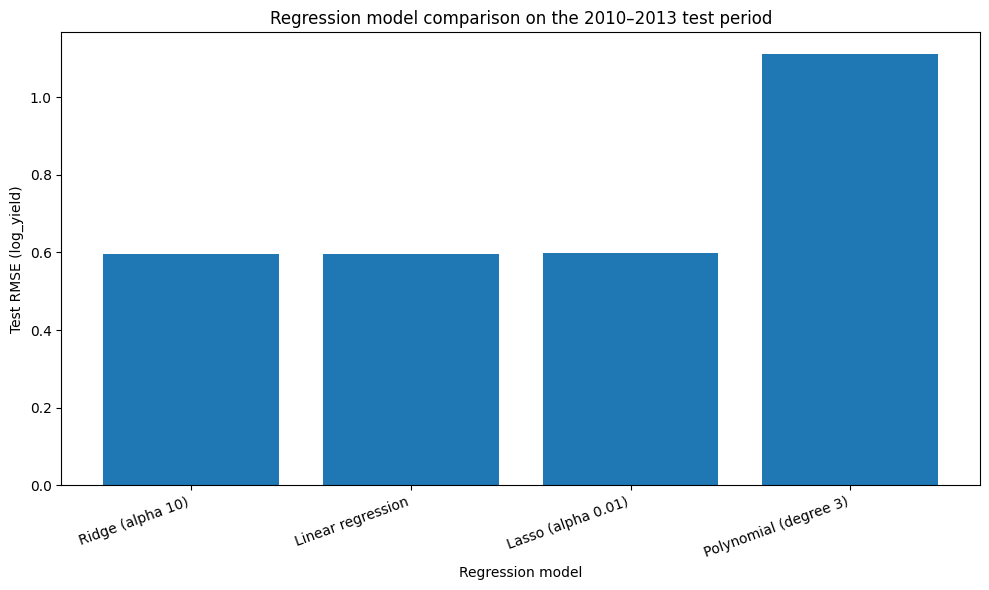

In [25]:
# Plot test RMSE for the four selected regression models and save the comparison chart.
plt.figure(figsize=(10, 6))
plt.bar(results_reg["model"], results_reg["test_RMSE"])
plt.ylabel("Test RMSE (log_yield)")
plt.xlabel("Regression model")
plt.title("Regression model comparison on the 2010–2013 test period")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(os.path.join(OUT, "regression_comparison.png"), dpi=150, bbox_inches="tight")
plt.show()

In [26]:
# Rank standardised Ridge coefficients to identify influential prepared features.
feature_importance = pd.DataFrame({
    "feature": X_train.columns,
    "coefficient": best_ridge_model.coef_,
    "absolute_coefficient": np.abs(best_ridge_model.coef_)
}).sort_values("absolute_coefficient", ascending=False)

print("Largest absolute standardised coefficients in the best Ridge model:")
display(feature_importance.head(10))

Largest absolute standardised coefficients in the best Ridge model:


,feature,coefficient,absolute_coefficient
7,Item_Potatoes,0.480706,0.480706
10,Item_Soybeans,-0.353396,0.353396
9,Item_Sorghum,-0.339723,0.339723
4,Item_Cassava,0.289788,0.289788
11,Item_Sweet potatoes,0.259039,0.259039
12,Item_Wheat,-0.223498,0.223498
2,avg_temp,-0.219271,0.219271
5,Item_Maize,-0.171971,0.171971
1,pesticides_t,0.162748,0.162748
13,Item_Yams,0.147036,0.147036


### Why can yield rise and then fall as temperature increases?

Crop growth generally benefits from warmth up to a crop-specific optimum because temperature supports processes such as germination, photosynthesis and development. Beyond the optimum, excessive heat can increase water loss, cause heat stress, shorten the grain-filling period and reduce pollination or fruit formation. Therefore, the relationship between average temperature and yield may be curved rather than a straight line. The optimum and the size of the effect differ by crop, location, rainfall and farming conditions.

In [27]:
# Generate the written findings from the measured test results rather than guessing scores.
best_overall = results_reg.iloc[0]
ridge_train_rmse = calculate_rmse(y_train, best_ridge_model.predict(X_train))
ridge_test_rmse = calculate_rmse(y_test, best_ridge_model.predict(X_test))
top_features = feature_importance.head(5)["feature"].tolist()

print("WRITTEN ANSWER — MODEL PERFORMANCE")
print(
    f"The best model on the 2010–2013 test set was {best_overall['model']} "
    f"with MAE={best_overall['test_MAE']:.4f}, RMSE={best_overall['test_RMSE']:.4f}, "
    f"and R²={best_overall['test_R2']:.4f}."
)
print(
    f"The selected Ridge model had training RMSE={ridge_train_rmse:.4f} "
    f"and test RMSE={ridge_test_rmse:.4f}; the difference is "
    f"{ridge_test_rmse-ridge_train_rmse:.4f}. A larger test error indicates a generalisation gap."
)
print("The largest absolute standardised Ridge coefficients were for:", ", ".join(top_features))
print("Use coefficient magnitude as an indication of influence, not proof of causation.")

WRITTEN ANSWER — MODEL PERFORMANCE
The best model on the 2010–2013 test set was Ridge (alpha 10) with MAE=0.4514, RMSE=0.5970, and R²=0.7099.
The selected Ridge model had training RMSE=0.5825 and test RMSE=0.5970; the difference is 0.0145. A larger test error indicates a generalisation gap.
The largest absolute standardised Ridge coefficients were for: Item_Potatoes, Item_Soybeans, Item_Sorghum, Item_Cassava, Item_Sweet potatoes
Use coefficient magnitude as an indication of influence, not proof of causation.


## Final checks

The following cell verifies the required graded-evidence variables and output images. Run the notebook from top to bottom before submission.

In [28]:
# Confirm the required variables and image files exist for grading.
required_variables = ["poly_results", "ridge_results", "lasso_results", "results_reg"]
for variable_name in required_variables:
    print(variable_name, "->", "OK" if variable_name in globals() else "MISSING")

required_images = ["under_over_fit.png", "regression_comparison.png"]
for image_name in required_images:
    image_path = os.path.join(OUT, image_name)
    print(image_name, "->", "FOUND" if os.path.exists(image_path) else "MISSING")

poly_results -> OK
ridge_results -> OK
lasso_results -> OK
results_reg -> OK
under_over_fit.png -> FOUND
regression_comparison.png -> FOUND


In [29]:

# Verify that all required Task 3.2 variables and output files exist.

required_variables = [
    "poly_results",
    "ridge_results",
    "lasso_results",
    "results_reg"
]

for variable in required_variables:
    print(f"{variable}:",
          "EXISTS" if variable in globals() else "MISSING")

required_files = [
    "under_over_fit.png",
    "regression_comparison.png"
]

for filename in required_files:
    filepath = os.path.join(OUT, filename)
    print(filename,
          "EXISTS" if os.path.exists(filepath) else "MISSING")

# Display the final regression comparison.
display(results_reg)


poly_results: EXISTS
ridge_results: EXISTS
lasso_results: EXISTS
results_reg: EXISTS
under_over_fit.png EXISTS
regression_comparison.png EXISTS


,model,test_MAE,test_RMSE,test_R2
0,Ridge (alpha 10),0.451414,0.597026,0.709904
1,Linear regression,0.451401,0.597030,0.709900
2,Lasso (alpha 0.01),0.452014,0.597419,0.709522
3,Polynomial (degree 3),0.908918,1.111108,-0.004771


In [30]:
print("POLYNOMIAL REGRESSION")
display(poly_results)

print("RIDGE REGRESSION")
display(ridge_results)

print("LASSO REGRESSION")
display(lasso_results)

POLYNOMIAL REGRESSION


,degree,train_RMSE,test_RMSE
0,1,1.097719,1.116247
1,2,1.097388,1.115533
2,3,1.092724,1.111108


RIDGE REGRESSION


,alpha,train_RMSE,test_RMSE
0,0.01,0.582543,0.597030
1,0.10,0.582543,0.597030
2,1.00,0.582543,0.597030
3,10.00,0.582543,0.597026


LASSO REGRESSION


,alpha,train_RMSE,test_RMSE,zero_coefficients
0,0.01,0.583650,0.597419,3
1,0.10,0.679431,0.700444,5
2,1.00,1.105094,1.122488,15
3,10.00,1.105094,1.122488,15
